# Diabetes Mellitus Prediction — Best Threshold Revision

This notebook keeps the original preprocessing, balancing methods, feature-selection method, and model settings unchanged.

**Threshold protocol used in this revision**
- Split data first into train, validation, and test.
- Feature selection is fitted using training data only.
- Train each model using the existing training/resampling setup.
- Obtain validation probabilities.
- Search thresholds from 0.10 to 0.90.
- Require validation recall **≥ 0.60**.
- Select the threshold with the highest validation F1.
- Use that same validation-derived threshold for validation predictions/metrics.
- Use that same threshold for test predictions and the test confusion matrix.
- Test data is not used to select the threshold.

**Pipeline note:** The original code performs IQR clipping before the train/validation/test split. This revision does **not** change that step.

# Diabetes Mellitus Prediction

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_selection import RFE
from sklearn.inspection import permutation_importance

from imblearn.over_sampling import RandomOverSampler, BorderlineSMOTE

from xgboost import XGBClassifier


## Import dataset

In [ ]:
df = pd.read_csv('/content/dataset.csv', delimiter=',')
df.head()


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,1.65,70.2,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,1.47,42.5,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,1.52,47.0,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,1.63,57.4,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,1.42,36.0,17.79,0,0,0,0,0,No


## EDA

In [ ]:
df.info()  # Udah bersih, ga ada missing value, tipe data udah sesuai

duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

if duplicates == 0:
    print("Insight: Tidak ada duplicate data")
else:
    print("Insight: Dataset memiliki duplicate data")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5288 entries, 0 to 5287
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     5288 non-null   int64  
 1   gender                  5288 non-null   object 
 2   pulse_rate              5288 non-null   int64  
 3   systolic_bp             5288 non-null   int64  
 4   diastolic_bp            5288 non-null   int64  
 5   glucose                 5288 non-null   float64
 6   height                  5288 non-null   float64
 7   weight                  5288 non-null   float64
 8   bmi                     5288 non-null   float64
 9   family_diabetes         5288 non-null   int64  
 10  hypertensive            5288 non-null   int64  
 11  family_hypertension     5288 non-null   int64  
 12  cardiovascular_disease  5288 non-null   int64  
 13  stroke                  5288 non-null   int64  
 14  diabetic                5288 non-null   

In [ ]:
cols = [
    'family_diabetes',
    'hypertensive',
    'family_hypertension',
    'cardiovascular_disease',
    'stroke'
]

df[cols] = df[cols].astype(bool)

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5288 entries, 0 to 5287
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     5288 non-null   int64  
 1   gender                  5288 non-null   object 
 2   pulse_rate              5288 non-null   int64  
 3   systolic_bp             5288 non-null   int64  
 4   diastolic_bp            5288 non-null   int64  
 5   glucose                 5288 non-null   float64
 6   height                  5288 non-null   float64
 7   weight                  5288 non-null   float64
 8   bmi                     5288 non-null   float64
 9   family_diabetes         5288 non-null   bool   
 10  hypertensive            5288 non-null   bool   
 11  family_hypertension     5288 non-null   bool   
 12  cardiovascular_disease  5288 non-null   bool   
 13  stroke                  5288 non-null   bool   
 14  diabetic                5288 non-null   

In [ ]:
df.columns  # Ga ada yang di drop karena ga ada ID


Index(['age', 'gender', 'pulse_rate', 'systolic_bp', 'diastolic_bp', 'glucose',
       'height', 'weight', 'bmi', 'family_diabetes', 'hypertensive',
       'family_hypertension', 'cardiovascular_disease', 'stroke', 'diabetic'],
      dtype='object')

In [ ]:
df.describe()


,age,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi
count,5288.000000,5288.000000,5288.000000,5288.000000,5288.000000,5288.000000,5288.000000,5288.000000
mean,45.745651,76.626135,133.996596,82.229576,7.563922,1.548886,53.644100,22.466581
std,13.422024,12.229319,22.231752,12.479007,2.944381,0.080328,10.076059,8.819898
min,21.000000,5.000000,62.000000,45.000000,0.000000,0.360000,3.000000,1.220000
25%,35.000000,69.000000,119.000000,73.000000,6.000000,1.520000,46.775000,19.620000
50%,45.000000,76.000000,130.000000,81.000000,6.930000,1.550000,53.000000,21.870000
75%,55.000000,84.000000,147.000000,90.000000,8.130000,1.600000,59.900000,24.472500
max,80.000000,133.000000,231.000000,119.000000,33.460000,1.960000,100.700000,574.130000


In [ ]:
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(include='object').columns
bool_cols = df.select_dtypes(include='bool').columns

print("Numeric columns:")
print(num_cols)

print("\nCategorical columns:")
print(cat_cols)

print("\nBoolean columns:")
print(bool_cols)


Numeric columns:
Index(['age', 'pulse_rate', 'systolic_bp', 'diastolic_bp', 'glucose', 'height',
       'weight', 'bmi'],
      dtype='object')

Categorical columns:
Index(['gender', 'diabetic'], dtype='object')

Boolean columns:
Index(['family_diabetes', 'hypertensive', 'family_hypertension',
       'cardiovascular_disease', 'stroke'],
      dtype='object')


In [ ]:
for col in cat_cols:
    print(df[col].value_counts())
    print('----' * 30)


gender
Female    3752
Male      1536
Name: count, dtype: int64
------------------------------------------------------------------------------------------------------------------------
diabetic
No     4946
Yes     342
Name: count, dtype: int64
------------------------------------------------------------------------------------------------------------------------


### Check distribution data

/tmp/ipykernel_1606/1762530989.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diabetic', data=df, palette='viridis')


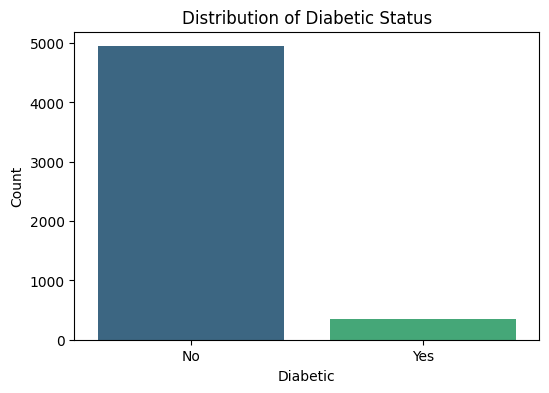

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='diabetic', data=df, palette='viridis')
plt.title('Distribution of Diabetic Status')
plt.xlabel('Diabetic')
plt.ylabel('Count')
plt.show()


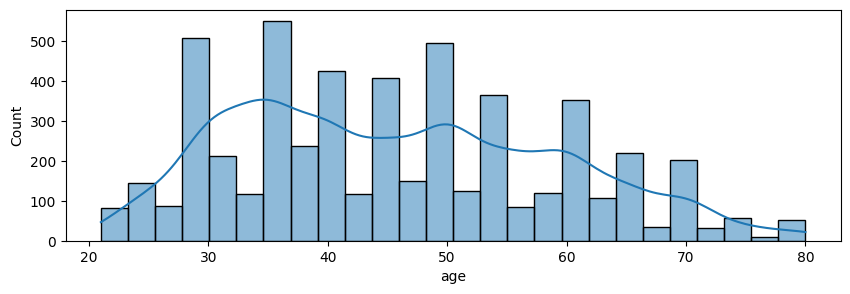

------------------------------------------------------------------------------------------


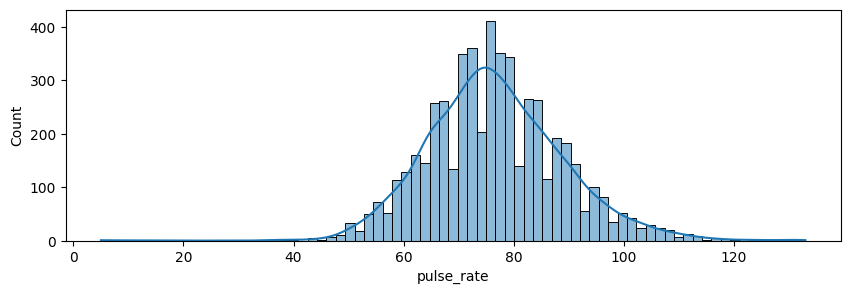

------------------------------------------------------------------------------------------


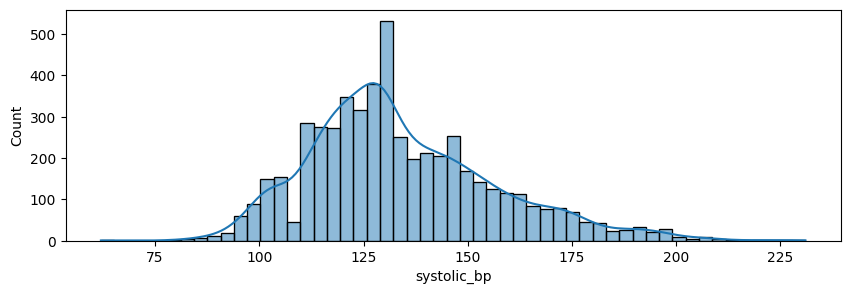

------------------------------------------------------------------------------------------


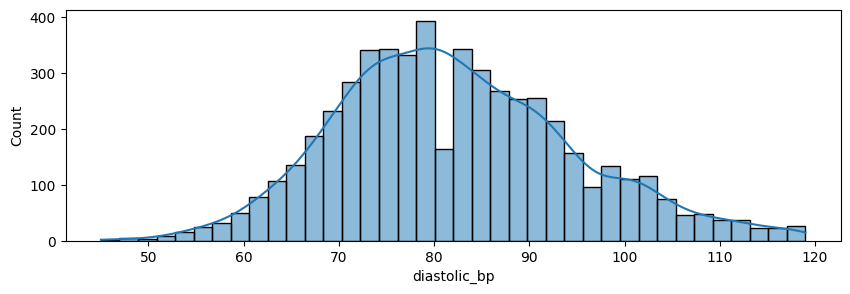

------------------------------------------------------------------------------------------


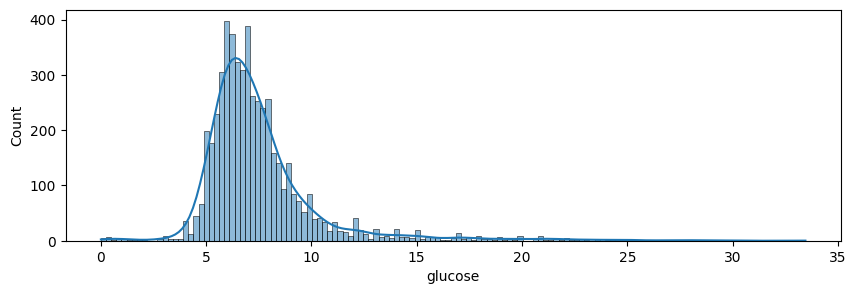

------------------------------------------------------------------------------------------


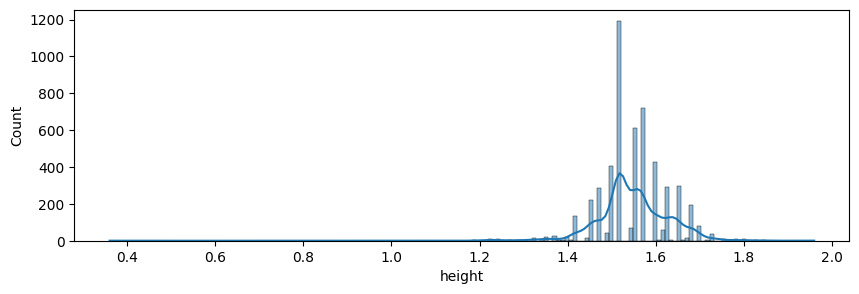

------------------------------------------------------------------------------------------


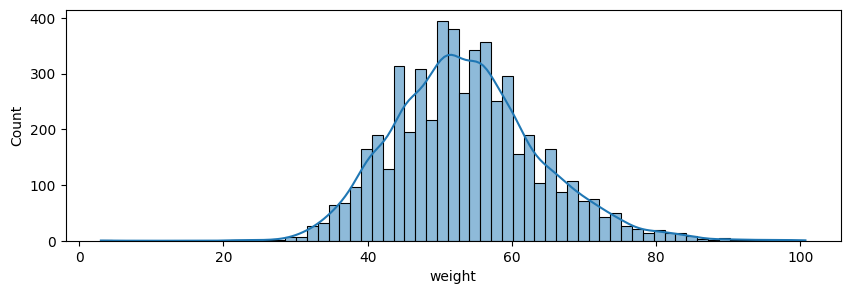

------------------------------------------------------------------------------------------


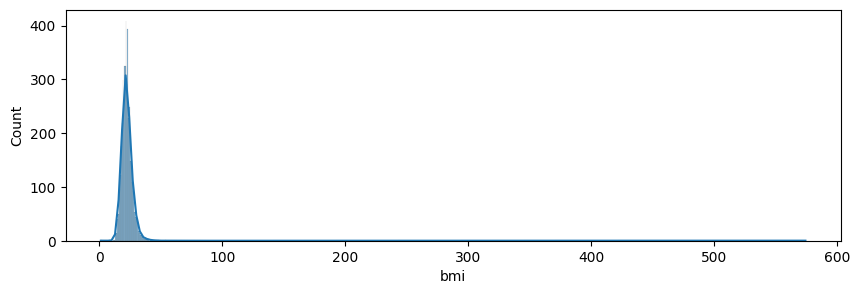

------------------------------------------------------------------------------------------


In [ ]:
for col in num_cols:
    plt.figure(figsize=(10, 3))
    sns.histplot(df[col], kde=True)
    plt.show()
    print('---' * 30)


### Check outliers

age


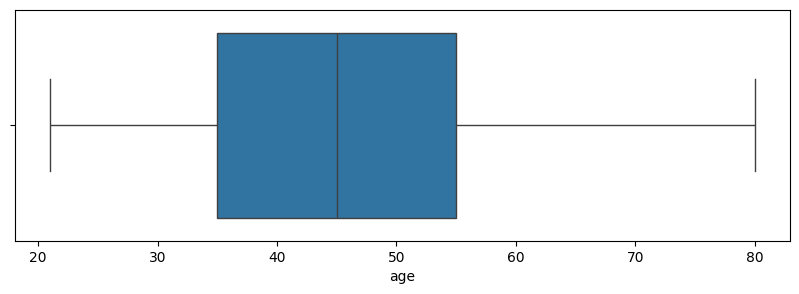

------------------------------------------------------------------------------------------
pulse_rate


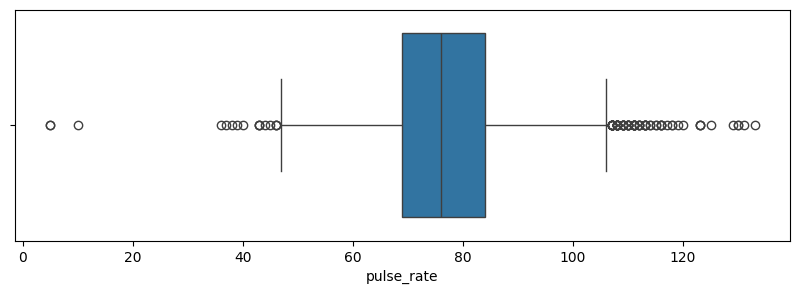

------------------------------------------------------------------------------------------
systolic_bp


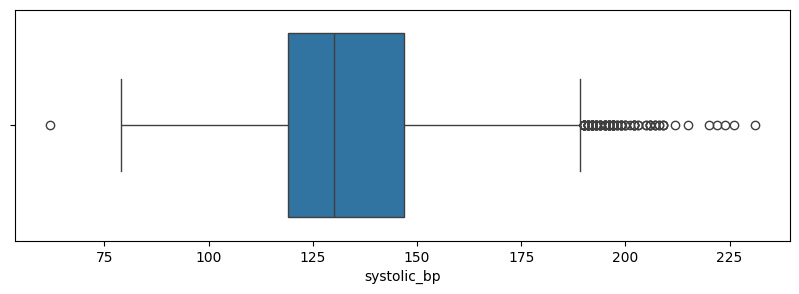

------------------------------------------------------------------------------------------
diastolic_bp


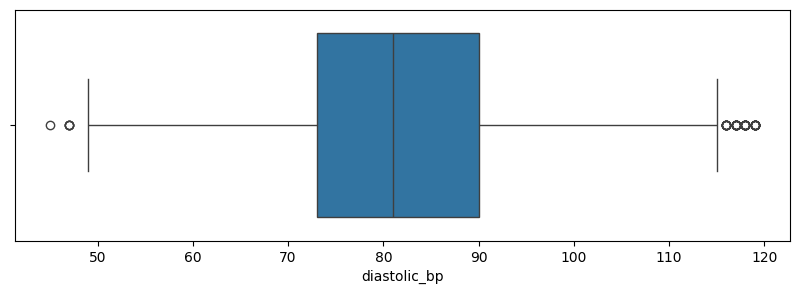

------------------------------------------------------------------------------------------
glucose


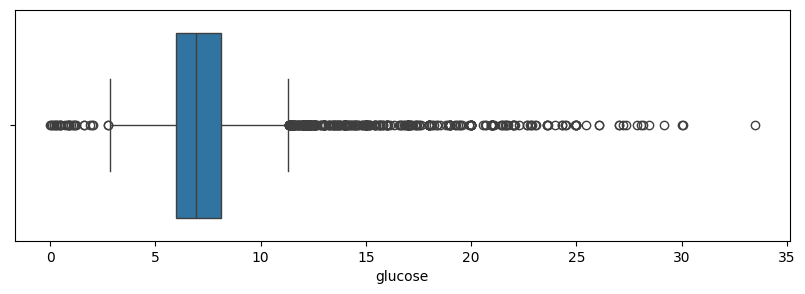

------------------------------------------------------------------------------------------
height


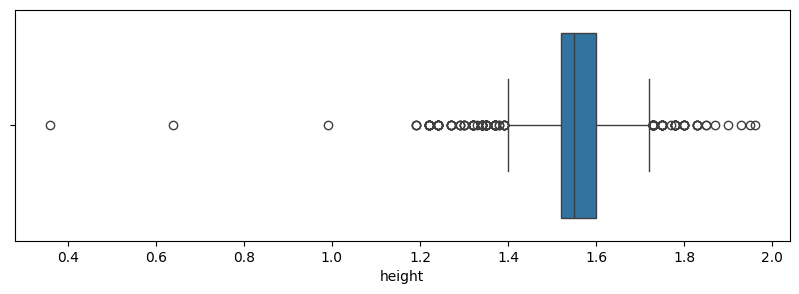

------------------------------------------------------------------------------------------
weight


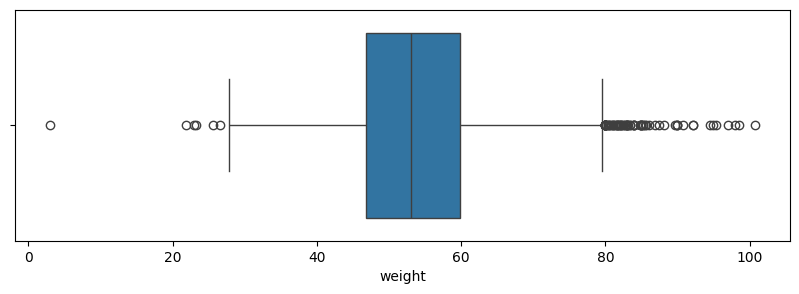

------------------------------------------------------------------------------------------
bmi


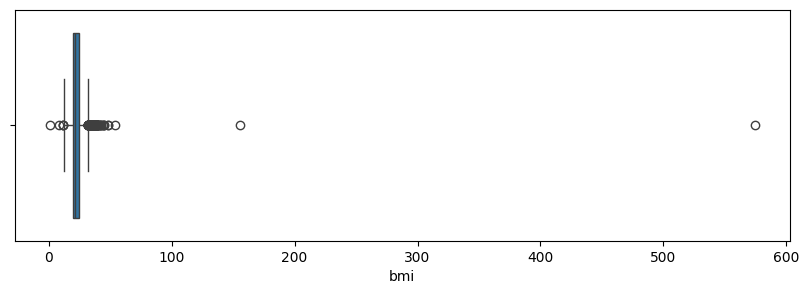

------------------------------------------------------------------------------------------


In [ ]:
for col in num_cols:
    print(col)
    plt.figure(figsize=(10, 3))
    sns.boxplot(df[col], orient='h')
    plt.show()
    print('---' * 30)


In [ ]:
num_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if df[col].nunique() > 2
]

outlier_dict = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_dict[col] = len(outliers)

outlier_table = pd.DataFrame.from_dict(
    outlier_dict,
    orient="index",
    columns=["Outlier Count"]
)

print(outlier_table)


              Outlier Count
age                       0
pulse_rate               96
systolic_bp             113
diastolic_bp             54
glucose                 400
height                  193
weight                   79
bmi                     133


## Pre-processing

In [ ]:
outlier_table_before = outlier_table.copy()

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)


In [ ]:
outlier_dict_after = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_dict_after[col] = len(outliers)

outlier_table_after = pd.DataFrame.from_dict(
    outlier_dict_after,
    orient="index",
    columns=["Outlier Count"]
)

print(outlier_table_after)


              Outlier Count
age                       0
pulse_rate                0
systolic_bp               0
diastolic_bp              0
glucose                   0
height                    0
weight                    0
bmi                       0


age


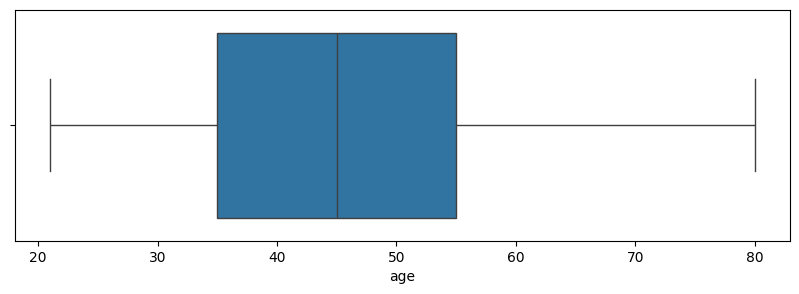

------------------------------------------------------------------------------------------
pulse_rate


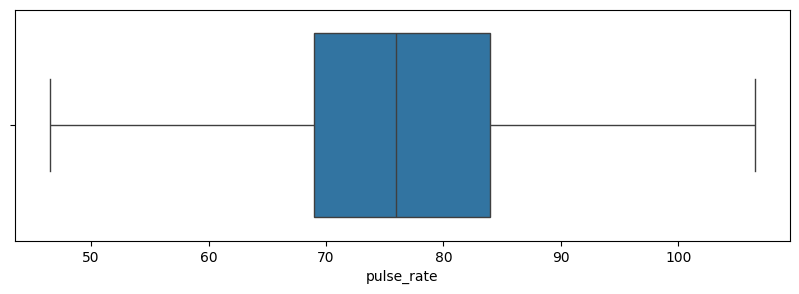

------------------------------------------------------------------------------------------
systolic_bp


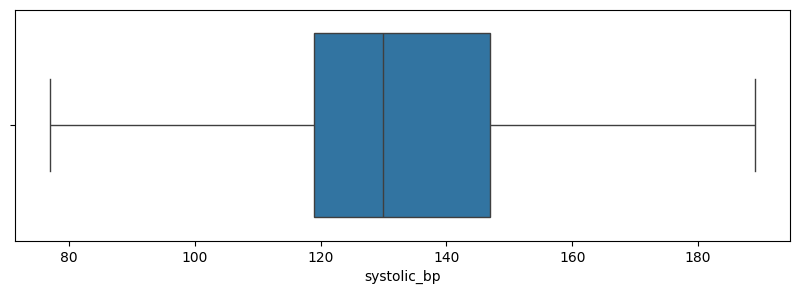

------------------------------------------------------------------------------------------
diastolic_bp


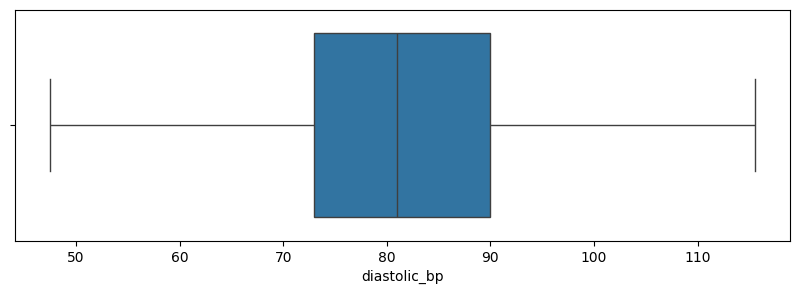

------------------------------------------------------------------------------------------
glucose


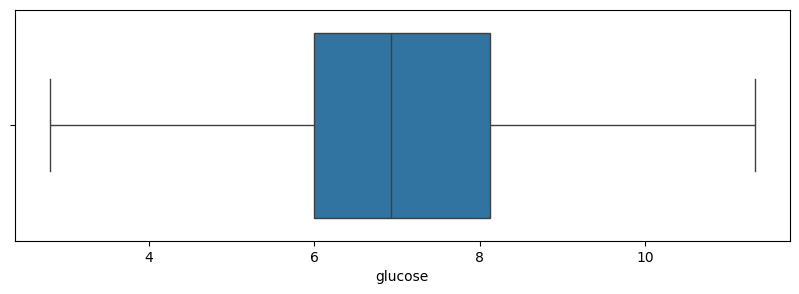

------------------------------------------------------------------------------------------
height


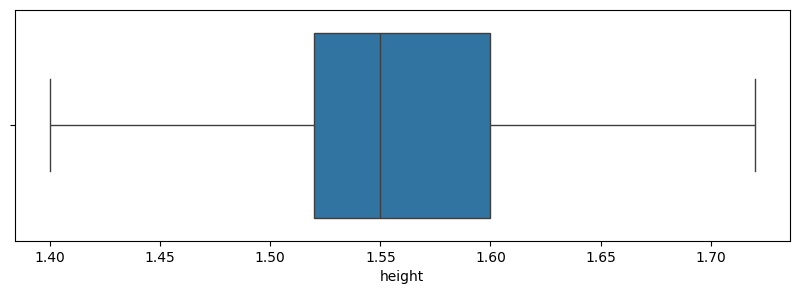

------------------------------------------------------------------------------------------
weight


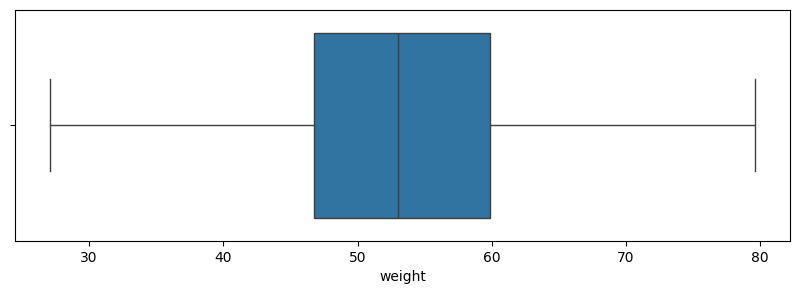

------------------------------------------------------------------------------------------
bmi


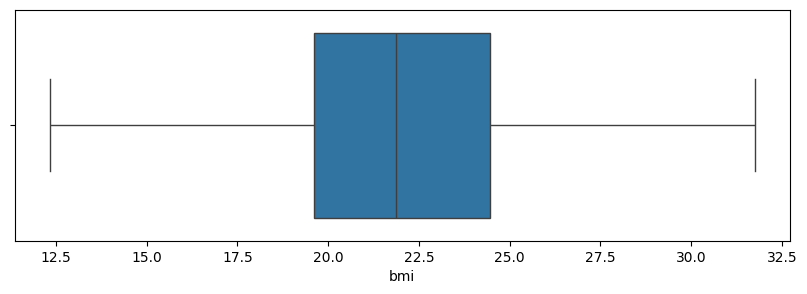

------------------------------------------------------------------------------------------


In [ ]:
for col in num_cols:
    print(col)
    plt.figure(figsize=(10, 3))
    sns.boxplot(df[col], orient='h')
    plt.show()
    print('---' * 30)


## Encoding

In [ ]:
df['gender'] = df['gender'].map({'Male': 0, 'Female': 1})
df['diabetic'] = df['diabetic'].map({'No': 0, 'Yes': 1})

df.head()


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,1,66.0,110,73.0,5.88,1.65,70.2,25.75,False,False,False,False,False,0
1,35,1,60.0,125,68.0,5.71,1.47,42.5,19.58,False,False,False,False,False,0
2,62,1,57.0,127,74.0,6.85,1.52,47.0,20.24,False,False,False,False,False,0
3,73,0,55.0,189,112.0,6.28,1.63,57.4,21.72,False,False,False,False,False,0
4,68,1,71.0,150,81.0,5.71,1.42,36.0,17.79,False,False,False,False,False,0


## Prepare features and target for data splitting

In [ ]:
X = df.drop('diabetic', axis=1)
y = df['diabetic']


## Split Data

In [ ]:
# ============================================
# DATA AWAL (SEMUA FITUR)
# ============================================

X_full = X
y_full = y

# ============================================
# SPLIT DATA
# ============================================

# 70% Train
# 10% Validation
# 20% Test

X_train_full, X_temp_full, y_train, y_temp = train_test_split(
    X_full,
    y_full,
    test_size=0.3,
    stratify=y_full,
    random_state=42
)

X_val_full, X_test_full, y_val, y_test = train_test_split(
    X_temp_full,
    y_temp,
    test_size=2/3,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train_full.shape)
print("Validation:", X_val_full.shape)
print("Test:", X_test_full.shape)


Train: (3701, 14)
Validation: (529, 14)
Test: (1058, 14)


## Feature Selection — Training Data Only


Correlation with Target:
hypertensive              0.373743
glucose                   0.253331
systolic_bp               0.169220
diastolic_bp              0.155804
cardiovascular_disease    0.102080
age                       0.099367
weight                    0.099313
bmi                       0.091107
pulse_rate                0.050738
height                    0.036095
stroke                    0.035149
family_hypertension      -0.008331
family_diabetes          -0.017395
gender                   -0.018516
Name: diabetic, dtype: float64

Top 5 Features:
hypertensive              0.373743
glucose                   0.253331
systolic_bp               0.169220
diastolic_bp              0.155804
cardiovascular_disease    0.102080
Name: diabetic, dtype: float64


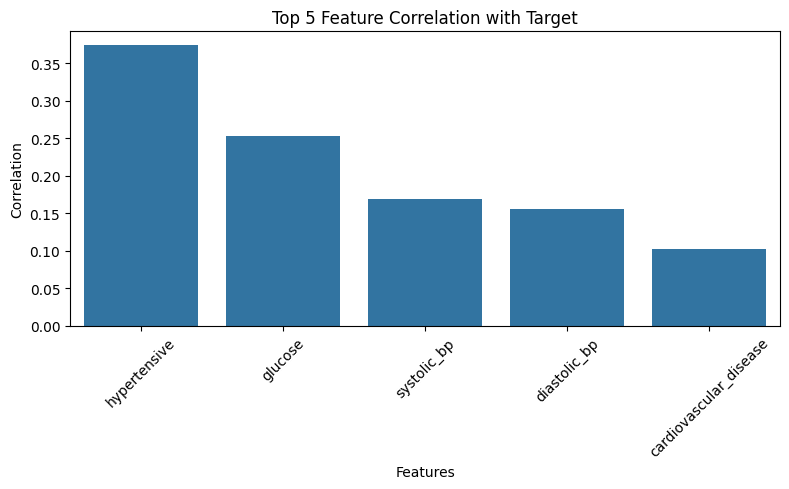

In [ ]:
# Correlation analysis using training data only
# Ini pearson correlation
train_fs_df = X_train_full.copy()
train_fs_df['diabetic'] = y_train.values

corr = train_fs_df.corr(numeric_only=True)

target = 'diabetic'

target_corr = corr[target].drop(target).sort_values(ascending=False)

print("\nCorrelation with Target:")
print(target_corr)

# Select top 5 features
top_features = target_corr.abs().sort_values(ascending=False).head(5)

print("\nTop 5 Features:")
print(top_features)

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(x=top_features.index, y=top_features.values)

plt.title("Top 5 Feature Correlation with Target")
plt.xlabel("Features")
plt.ylabel("Correlation")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# Random Forest feature importance (RFFI) fitted on training data only
model = RandomForestClassifier()
model.fit(X_train_full, y_train)

importances = pd.Series(
    model.feature_importances_,
    index=X_train_full.columns
)

print(importances.sort_values(ascending=False))


glucose                   0.198576
hypertensive              0.110753
bmi                       0.108895
systolic_bp               0.102912
pulse_rate                0.094809
weight                    0.094670
diastolic_bp              0.094327
age                       0.084907
height                    0.074994
gender                    0.017029
cardiovascular_disease    0.008984
family_hypertension       0.004589
family_diabetes           0.002746
stroke                    0.001808
dtype: float64


In [ ]:
# L1 Logistic Regression fitted on training data only
l1_model = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    max_iter=1000
)

l1_model.fit(X_train_full, y_train)

coef = pd.Series(
    l1_model.coef_[0],
    index=X_train_full.columns
)

selected_l1 = coef[coef != 0].sort_values(ascending=False)

print("Selected features (L1):")
print(selected_l1)


Selected features (L1):
hypertensive              2.317460
cardiovascular_disease    0.538035
glucose                   0.430419
weight                    0.047781
diastolic_bp              0.014540
pulse_rate                0.010910
age                       0.007603
systolic_bp               0.002302
family_diabetes          -0.045338
bmi                      -0.058473
stroke                   -0.062282
gender                   -0.181297
height                   -2.431225
dtype: float64


In [ ]:
# Model untuk RFE nya random forest
rfe_model = RandomForestClassifier(random_state=42)

# Pilih jumlah fitur (misalnya 5 dulu)
rfe = RFE(
    estimator=rfe_model,
    n_features_to_select=5
)

rfe.fit(X_train_full, y_train)

selected_rfe = X_train_full.columns[rfe.support_]

print("Selected features (RFE):")
print(selected_rfe)


Selected features (RFE):
Index(['systolic_bp', 'diastolic_bp', 'glucose', 'weight', 'bmi'], dtype='object')


In [ ]:
print("Random Forest Top Features:")
print(importances.sort_values(ascending=False))

print("\nL1 Selected Features:")
print(selected_l1.sort_values(ascending=False))

print("\nRFE Selected Features:")
print(selected_rfe)


Random Forest Top Features:
glucose                   0.198576
hypertensive              0.110753
bmi                       0.108895
systolic_bp               0.102912
pulse_rate                0.094809
weight                    0.094670
diastolic_bp              0.094327
age                       0.084907
height                    0.074994
gender                    0.017029
cardiovascular_disease    0.008984
family_hypertension       0.004589
family_diabetes           0.002746
stroke                    0.001808
dtype: float64

L1 Selected Features:
hypertensive              2.317460
cardiovascular_disease    0.538035
glucose                   0.430419
weight                    0.047781
diastolic_bp              0.014540
pulse_rate                0.010910
age                       0.007603
systolic_bp               0.002302
family_diabetes          -0.045338
bmi                      -0.058473
stroke                   -0.062282
gender                   -0.181297
height                  

### Weighted Voting (Vote + Correlation)

In [ ]:
from collections import Counter

# Siapin set dari metode correlation analysis
set_corr = set(top_features.index)
set_rf = set(importances.sort_values(ascending=False).head(5).index)
set_l1 = set(selected_l1.index)
set_rfe = set(selected_rfe)

# Hitung votenya
all_features = list(set_corr) + list(set_rf) + list(set_l1) + list(set_rfe)
counts = Counter(all_features)

vote_score = pd.Series(counts)

# Normalisasi correlation
corr_score = target_corr.abs()
corr_score = corr_score / corr_score.max()

# Align index
vote_score = vote_score.reindex(X_train_full.columns, fill_value=0)
corr_score = corr_score.reindex(X_train_full.columns, fill_value=0)

# Rumus final weighted score
final_score = vote_score * corr_score

# Ranking
final_ranking = final_score.sort_values(ascending=False)

# Normalisasi RF importance
rf_score = importances / importances.max()
rf_score = rf_score.reindex(X_train_full.columns, fill_value=0)

# Combine all
final_score = (vote_score * corr_score) + rf_score

final_ranking = final_score.sort_values(ascending=False)

print("Final Feature Ranking (Vote × Correlation + RF):")
print(final_ranking)

top5 = final_ranking.head(5).index.tolist()
top7 = final_ranking.head(7).index.tolist()
top10 = final_ranking.head(10).index.tolist()
top15 = final_ranking.head(15).index.tolist()


Final Feature Ranking (Vote × Correlation + RF):
glucose                   3.711282
hypertensive              3.557738
systolic_bp               2.329330
diastolic_bp              1.725640
bmi                       1.279689
weight                    1.008196
pulse_rate                0.748960
age                       0.693451
cardiovascular_disease    0.591502
height                    0.474237
gender                    0.135300
stroke                    0.103152
family_diabetes           0.060370
family_hypertension       0.023112
dtype: float64


In [ ]:
def evaluate(features):
    model = RandomForestClassifier(random_state=42)

    return cross_val_score(
        model,
        X_train_full[features],
        y_train,
        cv=5
    ).mean()

print("Top 5:", evaluate(top5))
print("Top 7:", evaluate(top7))
print("Top 10:", evaluate(top10))
print("Top 15:", evaluate(top15))

best_feature = top7

print("\nSelected feature set:")
print(best_feature)


Top 5: 0.9424481161323266
Top 7: 0.9462300762300762
Top 10: 0.9448798190903454
Top 15: 0.9467709815078236

Selected feature set:
['glucose', 'hypertensive', 'systolic_bp', 'diastolic_bp', 'bmi', 'weight', 'pulse_rate']


## Scaling

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_full)
X_val_scaled = scaler.transform(X_val_full)
X_test_scaled = scaler.transform(X_test_full)

# kembali menjadi dataframe
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train_full.columns
)

X_val_scaled = pd.DataFrame(
    X_val_scaled,
    columns=X_val_full.columns
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test_full.columns
)


## Random Oversampler

In [ ]:
ros = RandomOverSampler(
    sampling_strategy=0.2,
    random_state=42
)

X_ros, y_ros = ros.fit_resample(
    X_train_scaled,
    y_train
)


## Borderline SMOTE

In [ ]:
bsmote = BorderlineSMOTE(
    sampling_strategy=0.3,
    random_state=42
)

X_train_resampled, y_train_resampled = bsmote.fit_resample(
    X_ros,
    y_ros
)


## Data Without Feature Selection

In [ ]:
X_train_no_fs = X_train_resampled
X_val_no_fs = X_val_scaled
X_test_no_fs = X_test_scaled


## Data With Feature Selection

In [ ]:
X_train_selected = X_train_resampled[best_feature]
X_val_selected = X_val_scaled[best_feature]
X_test_selected = X_test_scaled[best_feature]


## Check Class Distribution

In [ ]:
print("=== CLASS DISTRIBUTION AFTER SAMPLING ===")
print(pd.Series(y_train_resampled).value_counts())


=== CLASS DISTRIBUTION AFTER SAMPLING ===
diabetic
0    3462
1    1038
Name: count, dtype: int64


## Check Shape

In [ ]:
print("=== TANPA FEATURE SELECTION ===")
print(X_train_no_fs.shape)

print("\n=== DENGAN FEATURE SELECTION ===")
print(X_train_selected.shape)

total_samples = len(X_full)

train_count = len(X_train_full)
val_count = len(X_val_full)
test_count = len(X_test_full)

train_proportion = train_count / total_samples
val_proportion = val_count / total_samples
test_proportion = test_count / total_samples

print(f"Train set: {train_count} samples ({train_proportion:.2%})")
print(f"Validation set: {val_count} samples ({val_proportion:.2%})")
print(f"Test set: {test_count} samples ({test_proportion:.2%})")


=== TANPA FEATURE SELECTION ===
(4500, 14)

=== DENGAN FEATURE SELECTION ===
(4500, 7)
Train set: 3701 samples (69.99%)
Validation set: 529 samples (10.00%)
Test set: 1058 samples (20.01%)


## Modeling

### Without Feature Selection

In [ ]:
# ============================================
# MODELS - NO FEATURE SELECTION
# ============================================

rf_base = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    min_samples_leaf=50,
    random_state=42
)

lr_base = LogisticRegression(
    C=0.01,
    max_iter=1000,
    class_weight='balanced'
)

knn_base = KNeighborsClassifier(
    n_neighbors=100
)

xgb_base = XGBClassifier(
    n_estimators=50,
    max_depth=2,
    reg_alpha=15,
    reg_lambda=15,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

stacking_full = StackingClassifier(
    estimators=[
        ('rf', rf_base),
        ('lr', lr_base),
        ('knn', knn_base),
        ('xgb', xgb_base)
    ],
    final_estimator=LogisticRegression(
        C=0.1,
        class_weight='balanced',
        max_iter=1000
    ),
    passthrough=True
)

models = {
    'Random Forest': rf_base,
    'Logistic Regression': lr_base,
    'KNN': knn_base,
    'XGBoost': xgb_base,
    'Ensemble Stacking': stacking_full
}


### Evaluation — No Feature Selection

**Important:** The complete `for` loop is kept in one cell. This prevents a `for` block from being accidentally split across cells.

In [ ]:
# ============================================
# EVALUATION - NO FEATURE SELECTION
# ============================================

results = []
thresholds_full = {}

for name, model in models.items():

    # --------------------------------------------
    # TRAIN
    # --------------------------------------------
    model.fit(
        X_train_no_fs,
        y_train_resampled
    )

    train_pred = model.predict(X_train_no_fs)

    train_acc = accuracy_score(
        y_train_resampled,
        train_pred
    )

    train_precision = precision_score(
        y_train_resampled,
        train_pred,
        zero_division=0
    )

    train_recall = recall_score(
        y_train_resampled,
        train_pred,
        zero_division=0
    )

    train_f1 = f1_score(
        y_train_resampled,
        train_pred,
        zero_division=0
    )

    # --------------------------------------------
    # VALIDATION PROBABILITY
    # --------------------------------------------
    val_prob = model.predict_proba(X_val_no_fs)[:, 1]

    # --------------------------------------------
    # THRESHOLD TUNING USING VALIDATION SET ONLY
    # --------------------------------------------
    best_threshold = 0.5
    best_f1 = 0.0

    min_required_recall = 0.60
    thresholds = np.arange(0.10, 0.91, 0.01)

    for threshold in thresholds:

        val_pred_temp = (
            val_prob >= threshold
        ).astype(int)

        val_recall_temp = recall_score(
            y_val,
            val_pred_temp,
            zero_division=0
        )

        val_f1_temp = f1_score(
            y_val,
            val_pred_temp,
            zero_division=0
        )

        if val_recall_temp >= min_required_recall:

            if val_f1_temp > best_f1:
                best_f1 = val_f1_temp
                best_threshold = threshold

    # Save validation-derived threshold
    thresholds_full[name] = best_threshold

    # --------------------------------------------
    # VALIDATION PREDICTION
    # SAME THRESHOLD SELECTED ABOVE
    # --------------------------------------------
    val_pred = (
        val_prob >= best_threshold
    ).astype(int)

    val_acc = accuracy_score(
        y_val,
        val_pred
    )

    val_precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_recall = recall_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_f1 = f1_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_auc = roc_auc_score(
        y_val,
        val_prob
    )

    # --------------------------------------------
    # TEST PROBABILITY
    # --------------------------------------------
    test_prob = model.predict_proba(X_test_no_fs)[:, 1]

    # --------------------------------------------
    # TEST PREDICTION
    # SAME VALIDATION-DERIVED THRESHOLD
    # --------------------------------------------
    test_pred = (
        test_prob >= best_threshold
    ).astype(int)

    test_acc = accuracy_score(
        y_test,
        test_pred
    )

    test_precision = precision_score(
        y_test,
        test_pred,
        zero_division=0
    )

    test_recall = recall_score(
        y_test,
        test_pred,
        zero_division=0
    )

    test_f1 = f1_score(
        y_test,
        test_pred,
        zero_division=0
    )

    test_auc = roc_auc_score(
        y_test,
        test_prob
    )

    # --------------------------------------------
    # F1 GAP
    # --------------------------------------------
    f1_gap = abs(
        train_f1 - test_f1
    )

    print(f"\n{name}")
    print("Best Threshold :", round(best_threshold, 2))
    print("Validation F1  :", round(val_f1, 4))

    results.append({
        'Model': name,
        'Best Threshold': round(best_threshold, 2),

        'Train Accuracy': round(train_acc, 4),
        'Train Precision': round(train_precision, 4),
        'Train Recall': round(train_recall, 4),
        'Train F1': round(train_f1, 4),

        'Val Accuracy': round(val_acc, 4),
        'Val Precision': round(val_precision, 4),
        'Val Recall': round(val_recall, 4),
        'Val F1': round(val_f1, 4),
        'Val ROC-AUC': round(val_auc, 4),

        'Test Accuracy': round(test_acc, 4),
        'Test Precision': round(test_precision, 4),
        'Test Recall': round(test_recall, 4),
        'Test F1': round(test_f1, 4),
        'Test ROC-AUC': round(test_auc, 4),

        'F1 Gap': round(f1_gap, 4)
    })



Random Forest
Best Threshold : 0.39
Validation F1  : 0.4646

Logistic Regression
Best Threshold : 0.64
Validation F1  : 0.4545

KNN
Best Threshold : 0.4
Validation F1  : 0.4468

XGBoost
Best Threshold : 0.43
Validation F1  : 0.449

Ensemble Stacking
Best Threshold : 0.72
Validation F1  : 0.4731


In [ ]:
# ============================================
# RESULT TABLE - NO FEATURE SELECTION
# ============================================

comparison_full_df = pd.DataFrame(results)

print("=" * 100)
print("FULL FEATURE MODEL COMPARISON")
print("=" * 100)

display(
    comparison_full_df.sort_values(
        by='Test F1',
        ascending=False
    )
)


FULL FEATURE MODEL COMPARISON


,Model,Best Threshold,Train Accuracy,Train Precision,Train Recall,Train F1,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,F1 Gap
4,Ensemble Stacking,0.72,0.8138,0.5697,0.7871,0.6610,0.9074,0.3729,0.6471,0.4731,0.8680,0.8828,0.2932,0.5652,0.3861,0.8534,0.2749
3,XGBoost,0.43,0.8213,0.7303,0.3574,0.4799,0.8979,0.3438,0.6471,0.4490,0.8657,0.8715,0.2690,0.5652,0.3645,0.8423,0.1155
0,Random Forest,0.39,0.8298,0.8178,0.3372,0.4775,0.8998,0.3538,0.6765,0.4646,0.8755,0.8696,0.2587,0.5362,0.3491,0.8470,0.1284
2,KNN,0.40,0.8264,0.7182,0.4075,0.5200,0.9017,0.3500,0.6176,0.4468,0.8454,0.8762,0.2615,0.4928,0.3417,0.8400,0.1783
1,Logistic Regression,0.64,0.7829,0.5207,0.7399,0.6112,0.8866,0.3289,0.7353,0.4545,0.8598,0.8422,0.2216,0.5652,0.3184,0.8333,0.2929


## Modeling

### With Feature Selection

In [ ]:
# ============================================
# MODELS - WITH FEATURE SELECTION
# ============================================

rf_fs = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    min_samples_leaf=50,
    random_state=42
)

lr_fs = LogisticRegression(
    C=0.01,
    max_iter=1000,
    class_weight='balanced'
)

knn_fs = KNeighborsClassifier(
    n_neighbors=100
)

xgb_fs = XGBClassifier(
    n_estimators=50,
    max_depth=2,
    reg_alpha=15,
    reg_lambda=15,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

stacking_fs = StackingClassifier(
    estimators=[
        ('rf', rf_fs),
        ('lr', lr_fs),
        ('knn', knn_fs),
        ('xgb', xgb_fs)
    ],
    final_estimator=LogisticRegression(
        C=0.1,
        class_weight='balanced',
        max_iter=1000
    ),
    passthrough=True
)

models_fs = {
    'Random Forest': rf_fs,
    'Logistic Regression': lr_fs,
    'KNN': knn_fs,
    'XGBoost': xgb_fs,
    'Ensemble Stacking': stacking_fs
}


### Evaluation — With Feature Selection

**Important:** The complete `for` loop is kept in one cell, including training, threshold tuning, validation, and test evaluation.

In [ ]:
# ============================================
# EVALUATION - WITH FEATURE SELECTION
# ============================================

results_fs = []
thresholds_fs = {}

for name, model in models_fs.items():

    # --------------------------------------------
    # TRAIN
    # --------------------------------------------
    model.fit(
        X_train_selected,
        y_train_resampled
    )

    train_pred = model.predict(X_train_selected)

    train_acc = accuracy_score(
        y_train_resampled,
        train_pred
    )

    train_precision = precision_score(
        y_train_resampled,
        train_pred,
        zero_division=0
    )

    train_recall = recall_score(
        y_train_resampled,
        train_pred,
        zero_division=0
    )

    train_f1 = f1_score(
        y_train_resampled,
        train_pred,
        zero_division=0
    )

    # --------------------------------------------
    # VALIDATION PROBABILITY
    # --------------------------------------------
    val_prob = model.predict_proba(X_val_selected)[:, 1]

    # --------------------------------------------
    # THRESHOLD TUNING USING VALIDATION SET ONLY
    # --------------------------------------------
    best_threshold = 0.5
    best_f1 = 0.0

    min_required_recall = 0.60
    thresholds = np.arange(0.10, 0.91, 0.01)

    for threshold in thresholds:

        val_pred_temp = (
            val_prob >= threshold
        ).astype(int)

        val_recall_temp = recall_score(
            y_val,
            val_pred_temp,
            zero_division=0
        )

        val_f1_temp = f1_score(
            y_val,
            val_pred_temp,
            zero_division=0
        )

        if val_recall_temp >= min_required_recall:

            if val_f1_temp > best_f1:
                best_f1 = val_f1_temp
                best_threshold = threshold

    # Save validation-derived threshold
    thresholds_fs[name] = best_threshold

    # --------------------------------------------
    # VALIDATION PREDICTION
    # SAME THRESHOLD SELECTED ABOVE
    # --------------------------------------------
    val_pred = (
        val_prob >= best_threshold
    ).astype(int)

    val_acc = accuracy_score(
        y_val,
        val_pred
    )

    val_precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_recall = recall_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_f1 = f1_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_auc = roc_auc_score(
        y_val,
        val_prob
    )

    # --------------------------------------------
    # TEST PROBABILITY
    # --------------------------------------------
    test_prob = model.predict_proba(X_test_selected)[:, 1]

    # --------------------------------------------
    # TEST PREDICTION
    # SAME VALIDATION-DERIVED THRESHOLD
    # --------------------------------------------
    test_pred = (
        test_prob >= best_threshold
    ).astype(int)

    test_acc = accuracy_score(
        y_test,
        test_pred
    )

    test_precision = precision_score(
        y_test,
        test_pred,
        zero_division=0
    )

    test_recall = recall_score(
        y_test,
        test_pred,
        zero_division=0
    )

    test_f1 = f1_score(
        y_test,
        test_pred,
        zero_division=0
    )

    test_auc = roc_auc_score(
        y_test,
        test_prob
    )

    # --------------------------------------------
    # F1 GAP
    # --------------------------------------------
    f1_gap = abs(
        train_f1 - test_f1
    )

    print(f"\n{name}")
    print("Best Threshold :", round(best_threshold, 2))
    print("Validation F1  :", round(val_f1, 4))

    results_fs.append({
        'Model': name,
        'Best Threshold': round(best_threshold, 2),

        'Train Accuracy': round(train_acc, 4),
        'Train Precision': round(train_precision, 4),
        'Train Recall': round(train_recall, 4),
        'Train F1': round(train_f1, 4),

        'Val Accuracy': round(val_acc, 4),
        'Val Precision': round(val_precision, 4),
        'Val Recall': round(val_recall, 4),
        'Val F1': round(val_f1, 4),
        'Val ROC-AUC': round(val_auc, 4),

        'Test Accuracy': round(test_acc, 4),
        'Test Precision': round(test_precision, 4),
        'Test Recall': round(test_recall, 4),
        'Test F1': round(test_f1, 4),
        'Test ROC-AUC': round(test_auc, 4),

        'F1 Gap': round(f1_gap, 4)
    })



Random Forest
Best Threshold : 0.4
Validation F1  : 0.4404

Logistic Regression
Best Threshold : 0.67
Validation F1  : 0.4466

KNN
Best Threshold : 0.45
Validation F1  : 0.4421

XGBoost
Best Threshold : 0.45
Validation F1  : 0.4468

Ensemble Stacking
Best Threshold : 0.73
Validation F1  : 0.46


In [ ]:
# ============================================
# RESULT TABLE - WITH FEATURE SELECTION
# ============================================

comparison_fs_df = pd.DataFrame(results_fs)

print("=" * 100)
print("FEATURE SELECTION MODEL COMPARISON")
print("=" * 100)

display(
    comparison_fs_df.sort_values(
        by='Test F1',
        ascending=False
    )
)


FEATURE SELECTION MODEL COMPARISON


,Model,Best Threshold,Train Accuracy,Train Precision,Train Recall,Train F1,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,F1 Gap
4,Ensemble Stacking,0.73,0.8067,0.5610,0.7437,0.6396,0.8979,0.3485,0.6765,0.4600,0.8602,0.8762,0.2786,0.5652,0.3732,0.8497,0.2664
3,XGBoost,0.45,0.8207,0.7401,0.3430,0.4687,0.9017,0.3500,0.6176,0.4468,0.8633,0.8752,0.2667,0.5217,0.3529,0.8424,0.1158
2,KNN,0.45,0.8200,0.6733,0.4268,0.5224,0.8998,0.3443,0.6176,0.4421,0.8371,0.8752,0.2632,0.5072,0.3465,0.8355,0.1759
0,Random Forest,0.40,0.8378,0.7973,0.3979,0.5308,0.8847,0.3200,0.7059,0.4404,0.8646,0.8601,0.2484,0.5652,0.3451,0.8429,0.1857
1,Logistic Regression,0.67,0.7816,0.5191,0.7197,0.6031,0.8922,0.3333,0.6765,0.4466,0.8564,0.8554,0.2273,0.5072,0.3139,0.8299,0.2892


## Visualization

### Feature Importance — XGBoost

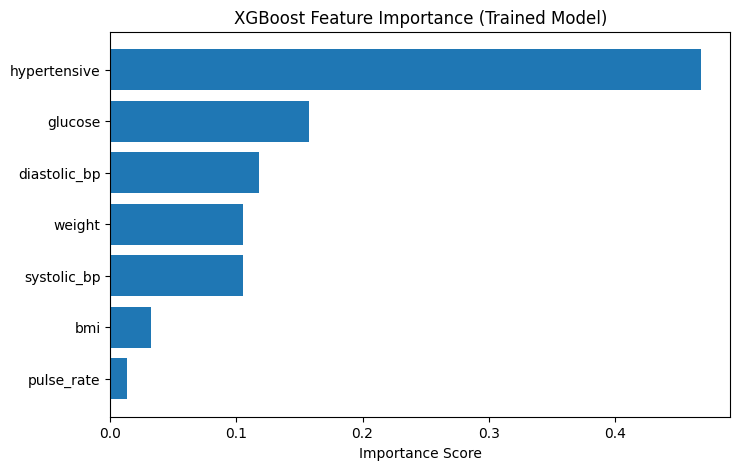

In [ ]:
# Use the trained XGBoost model from the FEATURE-SELECTION experiment.
trained_xgb = models_fs['XGBoost']

importance = trained_xgb.feature_importances_

feat_imp = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Importance': importance
}).sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(8, 5))
plt.barh(feat_imp['Feature'], feat_imp['Importance'])
plt.gca().invert_yaxis()
plt.title('XGBoost Feature Importance (Trained Model)')
plt.xlabel('Importance Score')
plt.show()


### Feature Importance — Random Forest

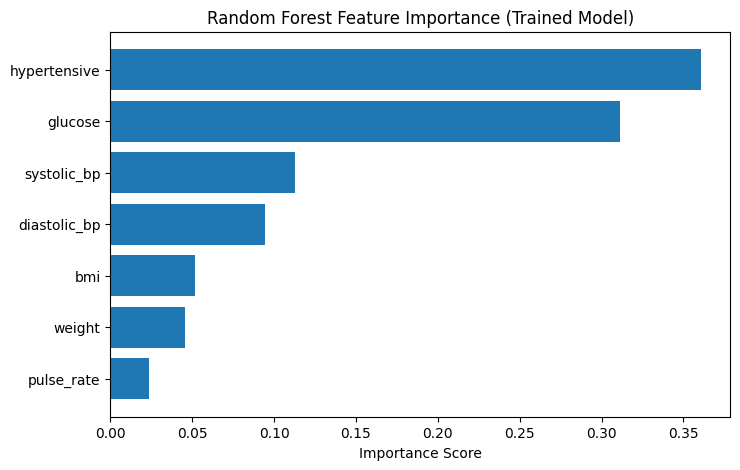

In [ ]:
# Use the trained Random Forest model from the FEATURE-SELECTION experiment.
trained_rf = models_fs['Random Forest']

importance_rf = trained_rf.feature_importances_

feat_imp_rf = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Importance': importance_rf
}).sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(8, 5))
plt.barh(feat_imp_rf['Feature'], feat_imp_rf['Importance'])
plt.gca().invert_yaxis()
plt.title('Random Forest Feature Importance (Trained Model)')
plt.xlabel('Importance Score')
plt.show()


### Logistic Regression Coefficients

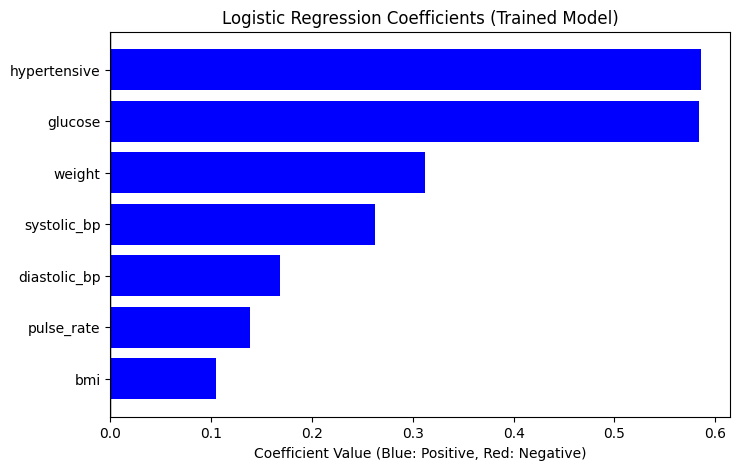

In [ ]:
# Use the trained Logistic Regression model from the FEATURE-SELECTION experiment.
trained_lr = models_fs['Logistic Regression']

coefficients = trained_lr.coef_[0]

lr_importance_df = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Coefficient': coefficients
})

lr_importance_df['Abs_Importance'] = (
    lr_importance_df['Coefficient'].abs()
)

lr_importance_df = lr_importance_df.sort_values(
    by='Abs_Importance',
    ascending=False
)

plt.figure(figsize=(8, 5))

colors = [
    'red' if x < 0 else 'blue'
    for x in lr_importance_df['Coefficient']
]

plt.barh(
    lr_importance_df['Feature'],
    lr_importance_df['Coefficient'],
    color=colors
)

plt.gca().invert_yaxis()
plt.axvline(
    x=0,
    color='black',
    linestyle='-',
    linewidth=1
)

plt.title('Logistic Regression Coefficients (Trained Model)')
plt.xlabel('Coefficient Value (Blue: Positive, Red: Negative)')
plt.show()


## Permutation Importance

### Ensemble Stacking

/tmp/ipykernel_1606/2498785475.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


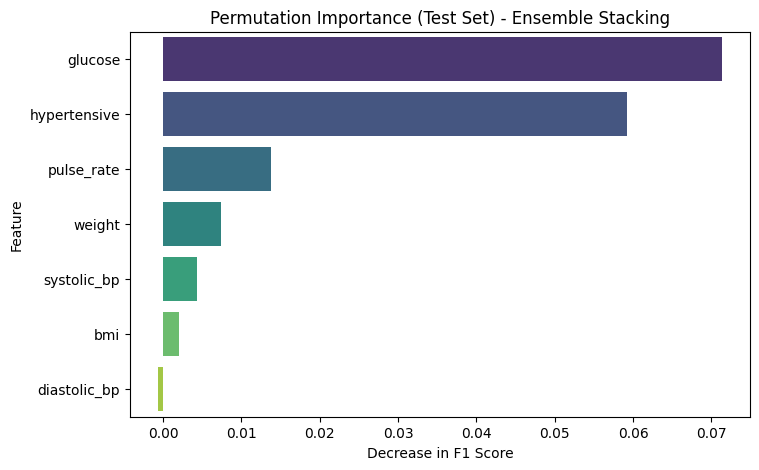

In [ ]:
# Use the trained stacking model from the FEATURE-SELECTION experiment.
stacking_model = models_fs['Ensemble Stacking']

# Calculate permutation importance using the test set and F1 score.
# This follows the original visualization setup.
perm_result = permutation_importance(
    stacking_model,
    X_test_selected,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='f1'
)

perm_importance_df = pd.DataFrame({
    'Feature': X_test_selected.columns,
    'Importance': perm_result.importances_mean
}).sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=perm_importance_df,
    x='Importance',
    y='Feature',
    palette='viridis'
)

plt.title('Permutation Importance (Test Set) - Ensemble Stacking')
plt.xlabel('Decrease in F1 Score')
plt.show()


## ROC Curve

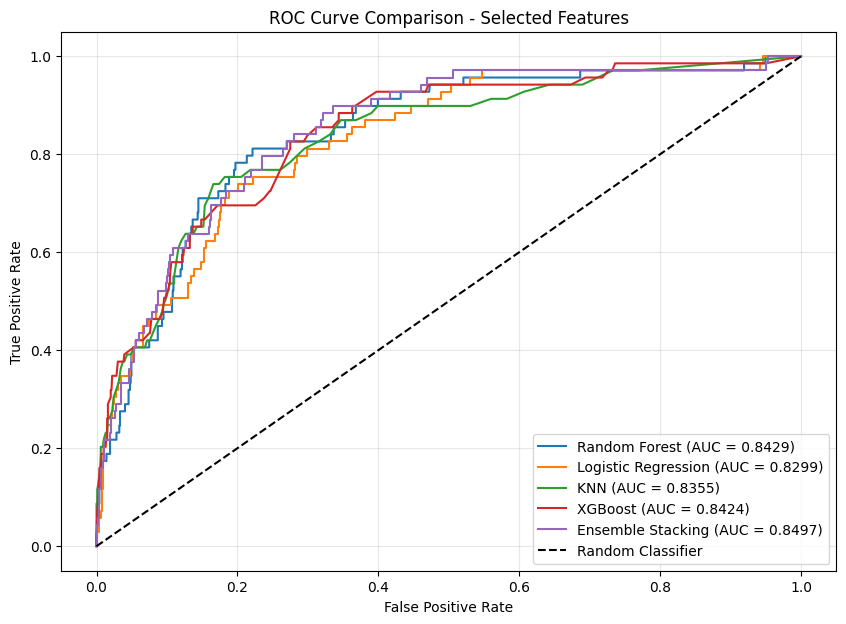

In [ ]:
plt.figure(figsize=(10, 7))

for name, model in models_fs.items():

    proba = model.predict_proba(
        X_test_selected
    )[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        proba
    )

    auc_score = roc_auc_score(
        y_test,
        proba
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.4f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - Selected Features')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


## Precision-Recall Curve

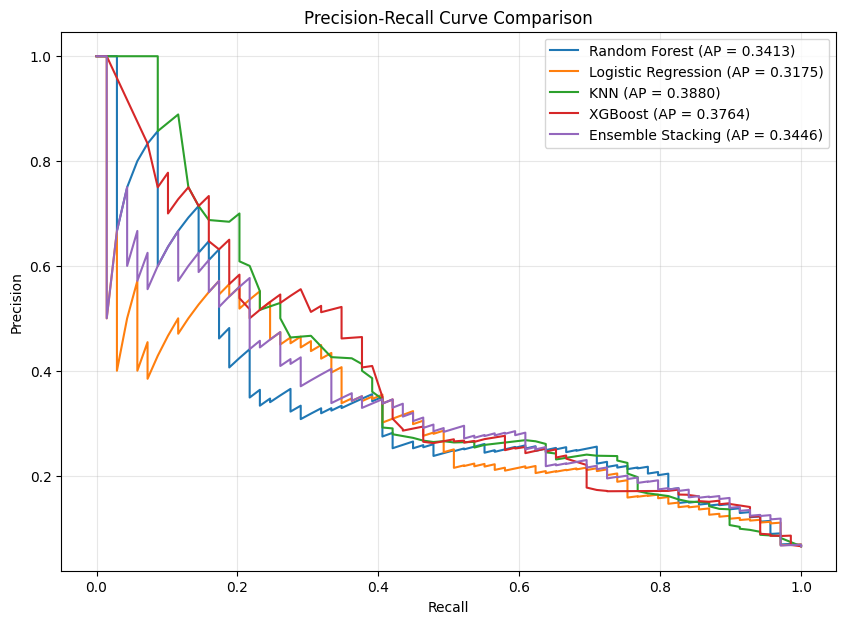

In [ ]:
plt.figure(figsize=(10, 7))

for name, model in models_fs.items():

    proba = model.predict_proba(
        X_test_selected
    )[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test,
        proba
    )

    ap_score = average_precision_score(
        y_test,
        proba
    )

    plt.plot(
        recall,
        precision,
        label=f'{name} (AP = {ap_score:.4f})'
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.show()


## Confusion Matrix

The confusion matrices below are **TEST confusion matrices**. Each test prediction uses the threshold selected from the validation set for that same model.

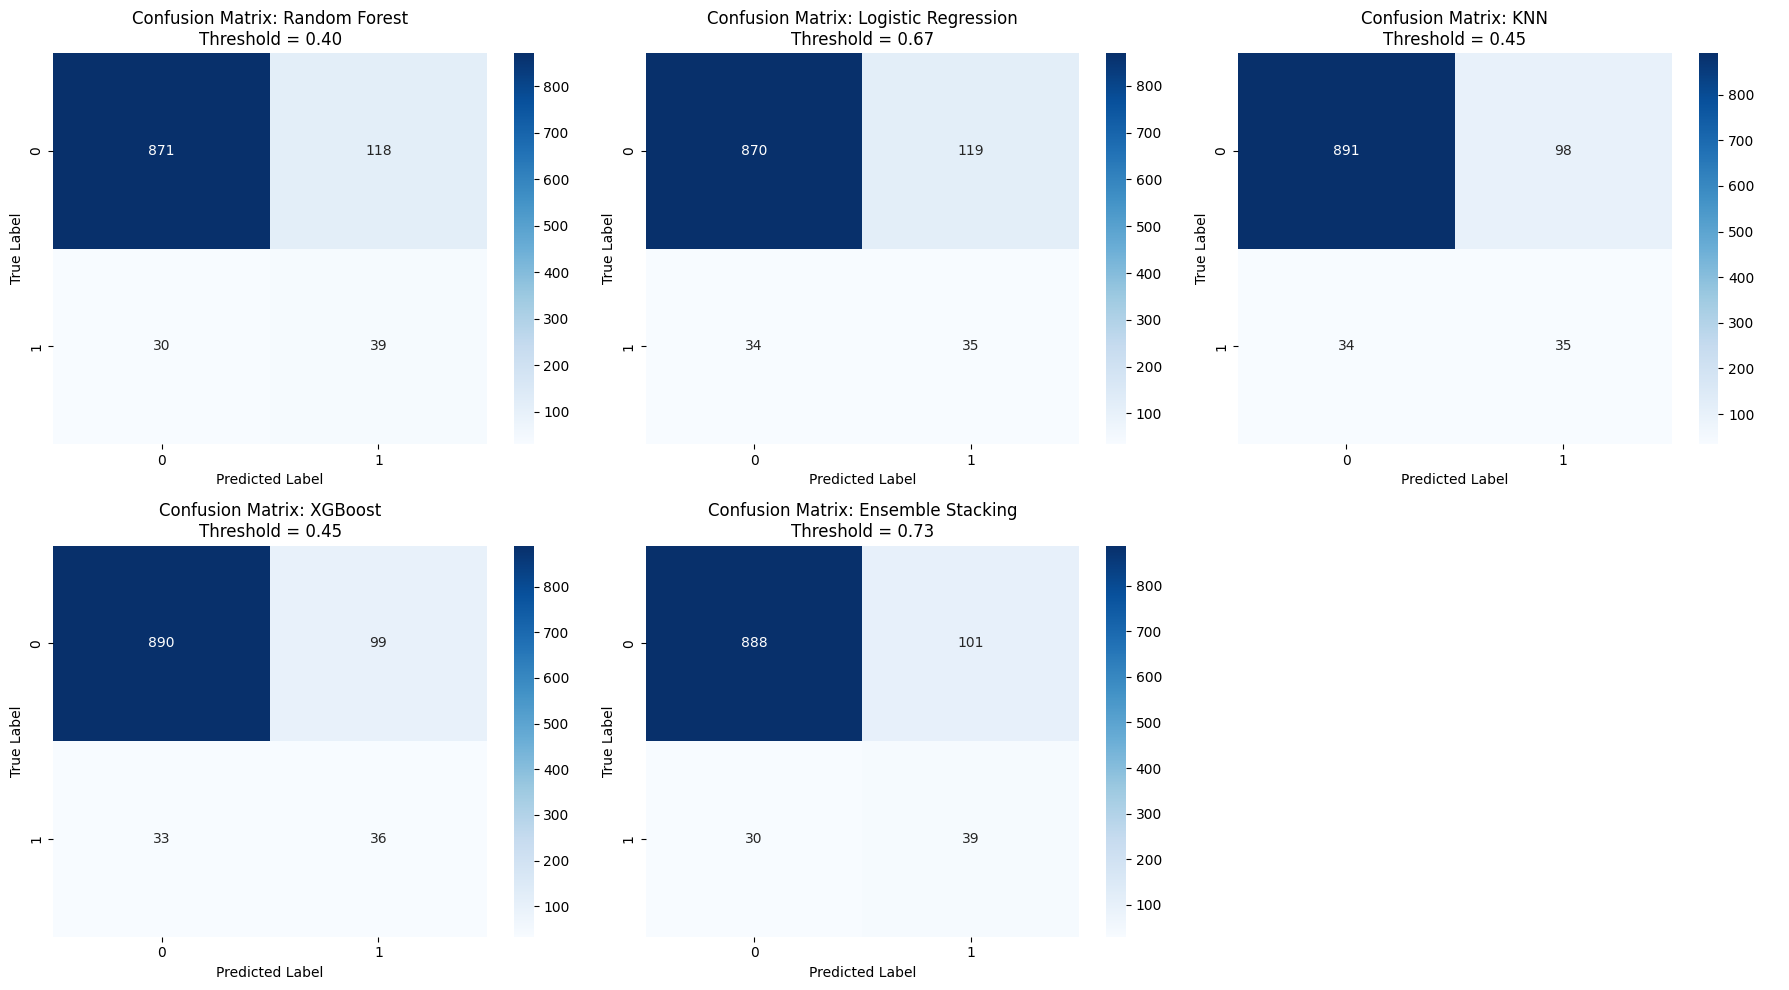

In [ ]:
# ============================================
# CONFUSION MATRIX - TEST SET
# WITH FEATURE SELECTION
# ============================================

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models_fs.items()):

    # Retrieve threshold selected using VALIDATION data.
    threshold = thresholds_fs[name]

    # Get TEST probabilities.
    test_prob = model.predict_proba(
        X_test_selected
    )[:, 1]

    # Apply the validation-derived threshold to TEST data.
    test_pred = (
        test_prob >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_test,
        test_pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i]
    )

    axes[i].set_title(
        f'Confusion Matrix: {name}\n'
        f'Threshold = {threshold:.2f}'
    )

    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

# Hide empty subplot if any.
if len(models_fs) < len(axes):
    for j in range(len(models_fs), len(axes)):
        axes[j].axis('off')

plt.tight_layout()
plt.show()


## Save Model

In [ ]:
from google.colab import files
import joblib

# Save the trained Ensemble Stacking model from the
# FEATURE-SELECTION experiment.
trained_model = models_fs['Ensemble Stacking']

joblib.dump(
    trained_model,
    'model.pkl'
)

files.download('model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>